# AICE Professional 주피터라이트 실전 모의고사 08회 — 공개데이터(배송 소요시간 · 세법 조문 세목 · 웨이퍼맵 불량 패턴)

## [ 필독 ] AICE Professional 모의고사 유의사항

- 공식 샘플문항(가공식품 카테고리 분류)과 **같은 시험지 형식**으로 만든 모의고사입니다. 3문항, 180분 기준입니다.
- 공식 시험과 같은 **Tabular / Text / Image 3유형**입니다. 2번 Text 문항은 공식 샘플(상품명 → 카테고리)과 같은 텍스트 분류입니다.
- 본인 스스로 모델을 만들고 **달성 목표 이상의 성능**이 나오도록 개발해야 합니다. 정답(테스트 라벨)은 제공되지 않습니다.
  대신 이 노트북 **맨 마지막 셀**(전체 자동 채점, 정답 키 인코딩)로 제출 파일을 스스로 채점할 수 있습니다(연습용).

## 사용할 수 있는 라이브러리 (주피터라이트 판)

이 모의고사는 **브라우저 주피터라이트(Pyodide · Python 3.14)** 에서 설치 없이 끝까지 풀 수 있도록 라이브러리를 제한했습니다.
필요한 라이브러리는 주피터라이트에 **미리 설치**되어 있습니다. 맨 위 '브라우저 실습' 셀은 확인만 하고 바로 끝납니다(Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다).

| 구분 | 쓸 수 있음 | 쓰지 않음(브라우저에서 안 됨) |
|---|---|---|
| 데이터·그림 | numpy · pandas · matplotlib · seaborn · Pillow | — |
| 머신러닝 | scikit-learn · LightGBM · XGBoost · imbalanced-learn · joblib | CatBoost |
| 텍스트 | scikit-learn 의 CountVectorizer · TfidfVectorizer · 내장 영어 불용어, **NLTK**(불용어·토큰화·어간 추출, 데이터는 `/drive/nltk_data` 에 미리 들어 있음) | 형태소 분석기 · BERT 등 사전학습 언어 모델 |
| 딥러닝 | `tensorflow.keras` 문법(TensorFlow.js 로 실행되는 대체 구현체, 미리 설치): `Sequential`·함수형(`Input` → 층 → `Model`) · Dense · Dropout · BatchNormalization · Conv2D · MaxPooling2D · GlobalAveragePooling2D · Embedding · LSTM · GRU · 콜백 3종(EarlyStopping · ModelCheckpoint · ReduceLROnPlateau) · `load_img` · `img_to_array` · `image_dataset_from_directory` · `ImageDataGenerator` · `model.save` / `load_model` · **MobileNet v1 전이학습**(`alpha=0.25`, 224×224, `weights='imagenet'` 만) | PyTorch · 다른 사전학습 모델(MobileNetV2/V3 · ResNet · EfficientNet 등) · 사용자 정의 층·손실 · GPU |

- 이미지는 64×64 정도로 줄여 작은 CNN 을 직접 학습하거나, MobileNet v1(alpha 0.25)로 특징을 뽑아 분류기를 학습하세요(전이학습). 브라우저 TensorFlow.js 는 CPython TensorFlow 와 수치가 조금 달라 딥러닝 점수가 약간 다르게 나올 수 있습니다.
- 학습이 오래 걸리면 epoch 를 줄이거나 조기 종료(EarlyStopping)를 쓰세요. 최신 Chrome·Edge 를 권장합니다.

## 시간 배분(180분)

| 문항 | 권장 시간 | 먼저 할 일 |
|---|---|---|
| 1. Tabular (30점) | 50분 | `info()`·`describe()` 로 자료형·결측 확인 → 기본 모델로 제출 파일부터 만들기 |
| 2. Text (35점) | 60분 | 라벨 분포·문장 길이 확인 → TF-IDF + 선형 모델로 기준 점수 |
| 3. Image (35점) | 60분 | 압축 풀기·폴더 구조 확인 → 작은 CNN 으로 기준 점수 |
| 마무리 | 10분 | 제출 파일 6개 이름·열 구조 확인 → 맨 마지막 채점 셀 실행 |

## 시험 자원 가이드

| 구분 | 공식 시험 | 이 모의고사 |
|---|---|---|
| IDE | CPU 8 core · Memory 32G · GPU 1개(VRAM 16GB) | **브라우저 주피터라이트**(설치 없음, CPU) — Colab·로컬 Jupyter 에서도 그대로 실행됨 |
| SW | Python 3.10 · TensorFlow 2.13 · PyTorch 2.1 | Python 3.14(Pyodide) · scikit-learn · LightGBM · XGBoost · Keras 문법(TensorFlow.js) — 위 표의 라이브러리만 |

## 유의 사항

- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 제출 파일명은 **고정**입니다: `answer_1~3` 모델 파일과 `answer_1~3.csv`.


문제에 제시되는 가이드는 필수적으로 준수하여 주시기 바랍니다. 이를 준수하지 않을 경우 채점 제한 또는 0점 처리될 수 있으니
각별히 유의해 주시기 바랍니다.

#### **[학습 정보]**
- 학습 목표 : Tabular · Text · Image 예측 모델 3종을 만들어 달성 목표 이상의 예측 파일을 제출하고, 제출한 코드로 같은 모델이 재현되게 할 수 있다
- AICE 역량 : PT1·PT2 표 데이터 / PX1·PX2 텍스트 / PI1·PI2 이미지 / PS1 제출 파일 형식·재현성
- 제출 파일 : `answer_1~3` 모델 파일(.pkl · .h5 등)과 `answer_1~3.csv` — **파일명은 고정**입니다(이름을 바꾸면 채점되지 않음)

| 문항 | 문제 | 달성 목표 | 역량 | 기술 | 예상 시간 |
|---|---|---|---|---|---|
| 1. Tabular | 라스트마일 배송 소요시간 예측 | RMSE 120.3 이하 | PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | pandas, joblib | 50분 |
| 2. Text | 세법 조문 세목 분류(법인세·부가가치세·소득세) | 정확도 0.76 이상 | PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | pandas, scikit-learn(CountVectorizer, TfidfVectorizer, MultinomialNB, LinearSVC), joblib | 60분 |
| 3. Image | 웨이퍼맵 불량 패턴 분류(9종) | 정확도 0.83 이상 | PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | pandas, scikit-learn(GlobalAveragePooling2D, BatchNormalization), Keras(TensorFlow.js) | 60분 |

In [1]:
# (브라우저 실습) 주피터라이트에는 tensorflow(TensorFlow.js 대체 구현체)·scikit-learn·LightGBM 등이 미리 설치되어 있어 이 셀은 확인만 합니다.
# Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다.
import os, sys, importlib.util
if 'pyodide' in sys.modules:
    os.environ['AICE_IMG_DIR'] = '/tmp/aice_images/' + os.path.basename(os.getcwd())   # 이미지 압축은 메모리 폴더에 풂(빠름)
    if not ('tensorflow' in sys.modules or importlib.util.find_spec('tensorflow')):
        # 미리 설치되지 않은 사이트(패치 전 주피터라이트)에서만: 같은 폴더의 tfjs_keras.py 를 불러옵니다
        sys.path[:0] = [os.getcwd(), '/drive']
        import tfjs_keras
        await tfjs_keras.load()
print('준비 완료 — 다음 셀로 넘어가세요.')

준비 완료 — 다음 셀로 넘어가세요.


## 1. Tabular 문제 - 라스트마일 배송 소요시간 예측 (30점)

<sub>학습 목표: 라스트마일 배송 소요시간 예측 모델로 테스트 RMSE 120.3 이하을 달성할 수 있다 | 역량: PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | 기술: pandas, joblib | 난이도: 실전 | 예상 시간: 50분</sub>

### 문제 개요

택배 기사가 배송 주문을 수락한 뒤 고객에게 전달하기까지 걸린 시간(분)을 예측하는 회귀 문제입니다.

제공된 훈련 데이터셋을 활용해 회귀 모델을 개발하고, 테스트 데이터셋의 'delivery_minutes' 값을 예측하시기 바랍니다.

### 달성 목표

"01_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **RMSE 120.3 이하**를 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `01_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `01_test_x.csv`: 테스트 데이터셋입니다. 라벨('delivery_minutes') 값이 제외되어 있습니다.

**Label 정보**

- 'delivery_minutes' : 주문 수락 → 배송 완료까지 걸린 시간(분)

**Data 정보**

- 'order_id' : 주문 번호
- 'city' : 도시
- 'region_id' : 권역 번호
- 'courier_id' : 기사 번호
- 'aoi_id' : 배송지 구역(AOI) 번호
- 'aoi_type' : 배송지 구역 유형(주거·상업 등 코드)
- 'lng / lat' : 배송지 경도·위도
- 'accept_time' : 주문 수락 시각(월-일 시:분:초, 연도 없음)
- 'accept_gps_lng / accept_gps_lat' : 주문을 수락한 순간 기사의 GPS 경도·위도(일부 결측)

**데이터 출처** — LaDe (Cainiao 라스트마일 배송, Apache-2.0) — 5개 도시 배송 5,000건 중 당일 배송 건

### 데이터 예시

`01_train.csv`

| order_id | city | region_id | courier_id | aoi_id | aoi_type | lng | lat | … |
|---|---|---|---|---|---|---|---|---|
| 1295993 | Jilin | 31 | 4849 | 57286 | 1 | 126.579 | 43.8381 | … |
| 366589 | Chongqing | 11 | 3675 | 4685 | 14 | 106.652 | 29.6171 | … |
| 670022 | Jilin | 31 | 949 | 17754 | 1 | 126.587 | 43.8434 | … |

`01_test_x.csv`

| order_id | city | region_id | courier_id | aoi_id | aoi_type | lng | lat | … |
|---|---|---|---|---|---|---|---|---|
| 2004613 | Jilin | 31 | 435 | 30242 | 1 | 126.553 | 43.8722 | … |
| 2291810 | Hangzhou | 0 | 15 | 11148 | 1 | 120.185 | 30.2682 | … |
| 3738540 | Yantai | 86 | 1508 | 17540 | 14 | 121.389 | 37.4622 | … |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 라스트마일 배송 소요시간 예측 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_1.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('delivery_minutes') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_1.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 'delivery_minutes' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 'delivery_minutes' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- `accept_time` 은 연도가 없는 `MM-DD HH:MM:SS` 문자열입니다(2022년 자료).
- 평가 지표는 **RMSE**(낮을수록 좋음)입니다.

### 채점 진행 방식 안내

- 1번 문항 배점 : 30점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_1.csv 로 제출된 예측 데이터를 정답지와 대조하여, **RMSE 132.33 이하** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [2]:

import pandas as pd

train_1 = pd.read_csv('01_train.csv')
test_1 = pd.read_csv('01_test_x.csv')

print('데이터 크기')
display(pd.DataFrame({
    '구분': ['학습', '테스트'],
    '행 수': [len(train_1), len(test_1)],
    '컬럼 수': [train_1.shape[1], test_1.shape[1]]
}))

print('학습 데이터 미리보기')
display(train_1.head())

print('컬럼별 자료형')
display(train_1.dtypes.to_frame('자료형'))

print('결측치 확인')
display(pd.DataFrame({
    '학습 결측치': train_1[test_1.columns].isna().sum(),
    '테스트 결측치': test_1.isna().sum()
}))

print('배송 소요시간 분포')
display(train_1['delivery_minutes'].describe().to_frame('값'))

print('도시별 데이터 수')
display(train_1['city'].value_counts().to_frame('건수'))

print('주문 번호 중복')
print('학습:', train_1['order_id'].duplicated().sum())
print('테스트:', test_1['order_id'].duplicated().sum())

print('주문 수락 시각 예시')
print(train_1['accept_time'].head().tolist())


데이터 크기


,구분,행 수,컬럼 수
0,학습,3930,12
1,테스트,983,11


학습 데이터 미리보기


,order_id,city,region_id,courier_id,aoi_id,aoi_type,lng,lat,accept_time,accept_gps_lng,accept_gps_lat,delivery_minutes
0,1295993,Jilin,31,4849,57286,1,126.57874,43.83806,05-29 14:36:00,126.56618,43.87095,178
1,366589,Chongqing,11,3675,4685,14,106.65157,29.61714,05-15 13:23:00,106.66995,29.60411,186
2,670022,Jilin,31,949,17754,1,126.58658,43.84339,09-14 08:00:00,126.56591,43.87085,154
3,2897338,Yantai,86,1630,18436,1,121.45197,37.45010,08-24 10:30:00,121.38028,37.41120,186
4,4351545,Hangzhou,0,4490,9072,1,120.18547,30.26114,10-25 09:11:00,120.20597,30.28666,122


컬럼별 자료형


,자료형
order_id,int64
city,object
region_id,int64
courier_id,int64
aoi_id,int64
aoi_type,int64
lng,float64
lat,float64
accept_time,object
accept_gps_lng,float64


... (3 outputs left out)

,값
count,3930.000000
mean,202.047583
std,145.168943
min,1.000000
25%,90.000000
50%,163.000000
75%,280.000000
max,712.000000


도시별 데이터 수


,건수
city,
Shanghai,811
Yantai,800
Jilin,795
Hangzhou,795
Chongqing,729


주문 번호 중복
학습: 0
테스트: 0
주문 수락 시각 예시
['05-29 14:36:00', '05-15 13:23:00', '09-14 08:00:00', '08-24 10:30:00', '10-25 09:11:00']


In [3]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def haversine(lng1, lat1, lng2, lat2):
    lng1, lat1, lng2, lat2 = map(
        np.radians, [lng1, lat1, lng2, lat2]
    )
    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin((lng2 - lng1) / 2) ** 2
    )
    return 2 * 6371 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def create_features(df):
    X = df.drop(
        columns=['order_id', 'accept_time', 'delivery_minutes'],
        errors='ignore'
    ).copy()

    dt = pd.to_datetime(
        '2022-' + df['accept_time'],
        format='%Y-%m-%d %H:%M:%S'
    )

    X['accept_month'] = dt.dt.month
    X['accept_dayofweek'] = dt.dt.dayofweek
    X['accept_hour'] = dt.dt.hour + dt.dt.minute / 60
    X['accept_is_weekend'] = (dt.dt.dayofweek >= 5).astype(int)

    X['distance_km'] = haversine(
        df['accept_gps_lng'],
        df['accept_gps_lat'],
        df['lng'],
        df['lat']
    )

    invalid_gps = X['distance_km'] > 100

    X['gps_missing'] = (
        df['accept_gps_lng'].isna()
        | df['accept_gps_lat'].isna()
        | invalid_gps
    ).astype(int)

    X.loc[
        invalid_gps,
        ['accept_gps_lng', 'accept_gps_lat', 'distance_km']
    ] = np.nan

    for col in ['city', 'region_id', 'courier_id', 'aoi_id', 'aoi_type']:
        X[col] = X[col].astype(str)

    return X

X_1 = create_features(train_1)
X_test_1 = create_features(test_1)
y_1 = train_1['delivery_minutes']

X_train_1, X_valid_1, y_train_1, y_valid_1 = train_test_split(
    X_1, y_1,
    test_size=0.2,
    random_state=42
)

cat_cols_1 = [
    'city', 'region_id', 'courier_id', 'aoi_id', 'aoi_type'
]
num_cols_1 = [c for c in X_1.columns if c not in cat_cols_1]

preprocessor_1 = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols_1),
    ('category', OneHotEncoder(handle_unknown='ignore'), cat_cols_1)
])

print('데이터 분리 결과')
display(pd.DataFrame({
    '구분': ['학습', '검증', '테스트'],
    '행 수': [len(X_train_1), len(X_valid_1), len(X_test_1)],
    '특성 수': [
        X_train_1.shape[1],
        X_valid_1.shape[1],
        X_test_1.shape[1]
    ]
}))

print('생성된 특성')
display(X_train_1.head())

print('전처리 전 남아 있는 결측치')
display(X_1.isna().sum()[X_1.isna().sum() > 0].to_frame('결측치 수'))

print('GPS 거리 통계')
display(X_1['distance_km'].describe().to_frame('거리(km)'))


데이터 분리 결과


,구분,행 수,특성 수
0,학습,3144,15
1,검증,786,15
2,테스트,983,15


생성된 특성


,city,region_id,courier_id,aoi_id,aoi_type,lng,lat,accept_gps_lng,accept_gps_lat,accept_month,accept_dayofweek,accept_hour,accept_is_weekend,distance_km,gps_missing
2330,Hangzhou,0,606,2086,1,120.17364,30.26004,120.18547,30.28075,6,4,16.916667,0,2.567838,0
2638,Yantai,86,3135,24968,14,121.40973,37.42479,121.38014,37.41138,10,2,7.866667,0,3.008696,0
3189,Hangzhou,0,1276,2659,1,120.17639,30.26437,120.18537,30.28075,5,0,8.416667,0,2.015212,0
1922,Yantai,86,3418,13706,14,121.43471,37.45393,121.38019,37.41113,10,5,8.450000,1,6.769293,0
3596,Chongqing,10,1635,31858,14,108.71406,30.92901,108.71816,30.95597,10,6,8.900000,1,3.023209,0


전처리 전 남아 있는 결측치


,결측치 수
accept_gps_lng,15
accept_gps_lat,15
distance_km,15


GPS 거리 통계


,거리(km)
count,3915.000000
mean,3.886360
std,3.086695
min,0.023121
25%,2.118391
50%,2.849211
75%,4.492164
max,46.465996


In [4]:

from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
from lightgbm import LGBMRegressor

models_1 = {
    'Ridge': Ridge(alpha=20.0),

    'LightGBM': LGBMRegressor(
        n_estimators=300,
        learning_rate=0.04,
        num_leaves=15,
        min_child_samples=30,
        colsample_bytree=0.8,
        random_state=42,
        verbose=-1,
        n_jobs=2
    ),

    'ExtraTrees': ExtraTreesRegressor(
        n_estimators=150,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=2
    )
}

cv_1 = KFold(n_splits=3, shuffle=True, random_state=42)

results_1 = []
fitted_models_1 = {}

for name, model in models_1.items():
    pipeline = Pipeline([
        ('preprocess', clone(preprocessor_1)),
        ('model', model)
    ])

    cv_scores = -cross_val_score(
        pipeline,
        X_train_1,
        y_train_1,
        cv=cv_1,
        scoring='neg_root_mean_squared_error',
        n_jobs=1
    )

    pipeline.fit(X_train_1, y_train_1)

    valid_pred = pipeline.predict(X_valid_1)
    valid_rmse = np.sqrt(
        mean_squared_error(y_valid_1, valid_pred)
    )

    fitted_models_1[name] = pipeline

    results_1.append({
        '모델': name,
        'CV 평균 RMSE': round(cv_scores.mean(), 3),
        'CV 표준편차': round(cv_scores.std(), 3),
        '독립 검증 RMSE': round(valid_rmse, 3),
        '목표 120.3 달성': valid_rmse <= 120.3
    })

result_df_1 = pd.DataFrame(results_1)
result_df_1 = result_df_1.sort_values('CV 평균 RMSE')

display(result_df_1.reset_index(drop=True))


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,모델,CV 평균 RMSE,CV 표준편차,독립 검증 RMSE,목표 120.3 달성
0,ExtraTrees,117.809,3.404,117.081,True
1,LightGBM,118.909,1.787,112.847,True
2,Ridge,122.430,2.922,116.848,True


In [5]:

import joblib
from pathlib import Path
from sklearn.base import clone

model_path_1 = Path('candidate_1_lightgbm_v1.pkl')
csv_path_1 = Path('candidate_1_lightgbm_v1.csv')

if model_path_1.exists() or csv_path_1.exists():
    raise FileExistsError('후보 파일이 이미 존재합니다. 기존 파일을 보존하세요.')

final_model_1 = clone(fitted_models_1['LightGBM'])
final_model_1.fit(X_1, y_1)

pred_before_1 = final_model_1.predict(X_test_1)

joblib.dump(final_model_1, model_path_1)
loaded_model_1 = joblib.load(model_path_1)

pred_after_1 = loaded_model_1.predict(X_test_1)

assert np.allclose(pred_before_1, pred_after_1)

candidate_csv_1 = test_1.copy()
candidate_csv_1['delivery_minutes'] = pred_after_1
candidate_csv_1.to_csv(csv_path_1, index=False)

saved_csv_1 = pd.read_csv(csv_path_1)

assert len(saved_csv_1) == len(test_1)
assert saved_csv_1.columns.tolist() == (
    test_1.columns.tolist() + ['delivery_minutes']
)
assert saved_csv_1['order_id'].equals(test_1['order_id'])
assert saved_csv_1['delivery_minutes'].notna().all()
assert np.isfinite(saved_csv_1['delivery_minutes']).all()

pd.testing.assert_frame_equal(
    saved_csv_1[test_1.columns],
    test_1,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

assert np.allclose(
    saved_csv_1['delivery_minutes'].to_numpy(),
    pred_after_1
)

print('후보 파일 검증 결과')
display(pd.DataFrame({
    '확인 항목': [
        '전체 학습 행 수',
        '테스트 예측 행 수',
        '모델 저장 및 재불러오기',
        '저장 전후 예측 일치',
        'CSV 컬럼 및 행 순서',
        '예측 결측치',
        '예측 최솟값',
        '예측 최댓값'
    ],
    '결과': [
        len(X_1),
        len(pred_after_1),
        '정상',
        '일치',
        '정상',
        saved_csv_1['delivery_minutes'].isna().sum(),
        round(pred_after_1.min(), 3),
        round(pred_after_1.max(), 3)
    ]
}))

print('저장 파일:', model_path_1, csv_path_1)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


후보 파일 검증 결과


,확인 항목,결과
0,전체 학습 행 수,3930
1,테스트 예측 행 수,983
2,모델 저장 및 재불러오기,정상
3,저장 전후 예측 일치,일치
4,CSV 컬럼 및 행 순서,정상
5,예측 결측치,0
6,예측 최솟값,26.666
7,예측 최댓값,515.216


저장 파일: candidate_1_lightgbm_v1.pkl candidate_1_lightgbm_v1.csv


In [6]:

import shutil
import hashlib
from pathlib import Path

source_model = Path('candidate_1_lightgbm_v1.pkl')
source_csv = Path('candidate_1_lightgbm_v1.csv')

answer_model = Path('answer_1.pkl')
answer_csv = Path('answer_1.csv')

if not source_model.exists() or not source_csv.exists():
    raise FileNotFoundError('후보 파일을 찾을 수 없습니다.')

if answer_model.exists() or answer_csv.exists():
    raise FileExistsError('정식 제출 파일이 이미 존재합니다.')

shutil.copy2(source_model, answer_model)
shutil.copy2(source_csv, answer_csv)

def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert file_hash(source_model) == file_hash(answer_model)
assert file_hash(source_csv) == file_hash(answer_csv)

check_model = joblib.load(answer_model)
check_csv = pd.read_csv(answer_csv)

assert check_csv.columns.tolist() == (
    test_1.columns.tolist() + ['delivery_minutes']
)
assert len(check_csv) == len(test_1)
assert check_csv['order_id'].equals(test_1['order_id'])
assert check_csv['delivery_minutes'].notna().all()

check_pred = check_model.predict(X_test_1)

assert np.allclose(
    check_pred,
    check_csv['delivery_minutes'].to_numpy()
)

display(pd.DataFrame({
    '확인 항목': [
        '모델 파일',
        '예측 CSV',
        '모델 파일 복사 일치',
        'CSV 파일 복사 일치',
        '모델 예측값과 CSV 일치',
        '제출 데이터 행 수'
    ],
    '결과': [
        str(answer_model),
        str(answer_csv),
        '정상',
        '정상',
        '정상',
        len(check_csv)
    ]
}))


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,확인 항목,결과
0,모델 파일,answer_1.pkl
1,예측 CSV,answer_1.csv
2,모델 파일 복사 일치,정상
3,CSV 파일 복사 일치,정상
4,모델 예측값과 CSV 일치,정상
5,제출 데이터 행 수,983


<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

자료형·결측·정답 분포를 확인합니다. 번호·날짜 원문·누수 열은 빼고 범주형은 원-핫 인코딩합니다. '참고'의 파생 변수를 만든 뒤 선형 모델과 트리 모델(LightGBM 등)을 **교차검증 RMSE** 로 비교해 더 나은 쪽으로 전체 학습하세요.

- 이 문항의 핵심: `accept_time` 은 연도가 없는 `MM-DD HH:MM:SS` 문자열입니다(2022년 자료).

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `pandas`, `joblib`, `lightgbm`, `train_test_split`, `mean_squared_error`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 1번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
import ____
from sklearn.model_selection import ____
from sklearn.metrics import ____

train = pd.read_csv('01_train.csv')
test = pd.read_csv('01_test_x.csv')

def haversine(lng1, lat1, lng2, lat2):
    lng1, lat1, lng2, lat2 = map(np.radians, [lng1, lat1, lng2, lat2])
    a = np.sin((lat2 - lat1) / ____) ** ____ + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / ____) ** ____
    return ____ * ____ * np.arcsin(np.sqrt(a))

CITIES = sorted(train['____'].unique())


# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_1.pkl`(모델) · `answer_1.csv`(예측)

</details>

## 2. Text 문제 - 세법 조문 세목 분류(법인세·부가가치세·소득세) (35점)

<sub>학습 목표: 세법 조문 세목 분류(법인세·부가가치세·소득세) 모델로 테스트 정확도 0.76 이상을 달성할 수 있다 | 역량: PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | 기술: pandas, scikit-learn(CountVectorizer, TfidfVectorizer, MultinomialNB, LinearSVC), joblib | 난이도: 실전 | 예상 시간: 60분</sub>

### 문제 개요

세법의 조문 문장(항·호·목 한 단위, 평균 약 100자)으로 그 문장이 속한 **세목 3종**(법인세·부가가치세·소득세)을 분류하는 자연어 처리 문제입니다. 다른 세법의 조항을 인용하는 문장(예: '법 제137조에 따른 …')이 많아 단어 하나로는 구분되지 않습니다.

제공된 훈련 데이터셋을 활용해 텍스트 다중 분류(3종) 모델을 개발하고, 테스트 데이터셋의 '세목' 값을 예측하시기 바랍니다.

### 달성 목표

"02_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 76% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `02_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `02_test_x.csv`: 테스트 데이터셋입니다. 라벨('세목') 값이 제외되어 있습니다.

**Label 정보**

- '세목' : 법인세 / 부가가치세 / 소득세

**Data 정보**

- '조문' : 세법 조문 문장(앞 번호 '1.' '가.' 는 뗌)
- 'id' : 테스트 행 번호(테스트에만)

**데이터 출처** — 한국 세법 조문(HF xaikorea0/taxia-korean-tax-laws · Apache-2.0) — 2015~2020 법인세법·부가가치세법·소득세법(법·시행령·시행규칙)의 항·호·목 문장, 내용 중복 제거

### 데이터 예시

`02_train.csv`

| 조문 | 세목 |
|---|---|
| 원천징수의무자가 개인인 경우: 「소득세법」 제7조제1항제1호 및 제2호에 따른 소재지 | 법인세 |
| 다음 각 호의 어느 하나에 해당하는 주택과 그밖의 주택(이하 이 항에서 "일반주택"이라 한다)을 국내에 각각 1개씩 소유하고 있는 1세대가 일반주택을 양도하는 경우에는 국내에 1개의 주택을 소유하고 있는 것으로 보아 제154조제1항을 적용한다. | 소득세 |
| 법 제174조의2제2호의 경우: 주식등의 거래명세서 | 소득세 |

`02_test_x.csv`

| id | 조문 |
|---|---|
| 1 | 「부동산 가격공시에 관한 법률」에 따른 개별주택가격이 없는 단독주택의 경우에는 당해 주택과 구조ㆍ용도ㆍ이용상황 등 이용가치가 유사한 인근주택을 표준주택으로 보고 같은 법 제16조제6항에 따른 비준표에 따라 납세지 관할세무서장(납세지 관할세무서장과 당해 주택의 소재지를 관할하는 세무서장이 서로 다른 경우로서 납세지 관할세무서장의 요청이 있는 경우에는 당해 주택의 소재지를 관할하는 세무서장)이 평가한 가액 |
| 2 | 법 제99조제1항제1호나목에 따른 기준시가가 고시되기 전에 취득한 건물의 취득당시의 기준시가는 다음 산식에 의하여 계산한 가액으로 한다. 국세청장이 해당 자산에 대하여 최초로 고시한 기준시가 ×해당 건물의 취득연도ㆍ신축연도ㆍ구조ㆍ내용연수 등을 고려하여 국세청장이 고시한 기준율 |
| 3 | 원천징수세액이 1천원 미만인 소득(법 제93조제7호에 따른 국내원천 부동산등양도소득 및 같은 조 제9호에 따른 국내원천 유가증권양도소득은 제외한다) |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 세법 조문 세목 분류(법인세·부가가치세·소득세) 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_2.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('세목') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_2.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 '세목' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 '세목' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 단어 단위(`analyzer='word'`)와 문자 n-gram(`analyzer='char_wb'`)을 모두 비교해 보세요. 법령 문장은 길어 `sublinear_tf=True` 가 도움이 됩니다.
- '법 제○조', '영 제○조' 같은 인용 표현이 많습니다. 숫자를 지우는 정리가 효과가 있는지 검증 점수로 확인하세요.
- 평가 지표는 **정확도(Accuracy)** 입니다. 테스트 행 순서(`id`)를 그대로 유지해 제출하세요.

### 채점 진행 방식 안내

- 2번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_2.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 68.4% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [8]:

import pandas as pd

train_2 = pd.read_csv('02_train.csv')
test_2 = pd.read_csv('02_test_x.csv')

print('데이터 크기')
display(pd.DataFrame({
    '구분': ['학습', '테스트'],
    '행 수': [len(train_2), len(test_2)],
    '컬럼 수': [train_2.shape[1], test_2.shape[1]]
}))

print('학습 데이터 미리보기')
display(train_2.head(3))

print('컬럼별 자료형')
display(train_2.dtypes.to_frame('자료형'))

print('결측치 확인')
display(pd.DataFrame({
    '학습 결측치': train_2.isna().sum(),
    '테스트 결측치': test_2.isna().sum()
}))

print('세목별 정답 분포')
label_counts_2 = train_2['세목'].value_counts()

display(pd.DataFrame({
    '건수': label_counts_2,
    '비율(%)': (label_counts_2 / len(train_2) * 100).round(2)
}))

print('조문 길이 통계')
display(train_2['조문'].str.len().describe().to_frame('글자 수'))

print('중복 조문 확인')
display(pd.DataFrame({
    '확인 항목': ['학습 중복', '테스트 중복', '학습-테스트 중복'],
    '건수': [
        train_2['조문'].duplicated().sum(),
        test_2['조문'].duplicated().sum(),
        test_2['조문'].isin(train_2['조문']).sum()
    ]
}))

print('테스트 ID 확인')
print('중복 ID:', test_2['id'].duplicated().sum())
print('처음 5개 ID:', test_2['id'].head().tolist())


데이터 크기


,구분,행 수,컬럼 수
0,학습,4645,2
1,테스트,1162,2


학습 데이터 미리보기


,조문,세목
0,원천징수의무자가 개인인 경우: 「소득세법」 제7조제1항제1호 및 제2호에 따른 소재지,법인세
1,"다음 각 호의 어느 하나에 해당하는 주택과 그밖의 주택(이하 이 항에서 ""일반주택""...",소득세
2,법 제174조의2제2호의 경우: 주식등의 거래명세서,소득세


컬럼별 자료형


,자료형
조문,object
세목,object


... (5 outputs left out)

,글자 수
count,4645.000000
mean,104.827557
std,115.805951
min,15.000000
25%,46.000000
50%,78.000000
75%,131.000000
max,3732.000000


중복 조문 확인


,확인 항목,건수
0,학습 중복,0
1,테스트 중복,0
2,학습-테스트 중복,0


테스트 ID 확인
중복 ID: 0
처음 5개 ID: [1, 2, 3, 4, 5]


In [9]:

from sklearn.model_selection import train_test_split

def clean_text_2(series):
    return (
        series.fillna('')
        .astype(str)
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()
    )

X_2 = clean_text_2(train_2['조문'])
y_2 = train_2['세목'].copy()
X_test_2 = clean_text_2(test_2['조문'])

X_train_2, X_valid_2, y_train_2, y_valid_2 = train_test_split(
    X_2,
    y_2,
    test_size=0.2,
    random_state=42,
    stratify=y_2
)

print('데이터 분리 결과')
display(pd.DataFrame({
    '구분': ['학습', '검증', '테스트'],
    '데이터 수': [
        len(X_train_2),
        len(X_valid_2),
        len(X_test_2)
    ]
}))

print('학습·검증 정답 분포')
display(pd.DataFrame({
    '학습 건수': y_train_2.value_counts(),
    '검증 건수': y_valid_2.value_counts(),
    '학습 비율(%)': (
        y_train_2.value_counts(normalize=True) * 100
    ).round(2),
    '검증 비율(%)': (
        y_valid_2.value_counts(normalize=True) * 100
    ).round(2)
}))

print('전처리 전후 문장 예시')
display(pd.DataFrame({
    '원본': train_2['조문'].head(3),
    '전처리 후': X_2.head(3)
}))

print('전처리 결과 확인')
display(pd.DataFrame({
    '확인 항목': [
        '빈 문장 수',
        '학습·검증 조문 중복',
        '테스트 데이터 수',
        '정답 클래스 수'
    ],
    '결과': [
        (X_2 == '').sum(),
        X_train_2.isin(X_valid_2).sum(),
        len(X_test_2),
        y_2.nunique()
    ]
}))


데이터 분리 결과


,구분,데이터 수
0,학습,3716
1,검증,929
2,테스트,1162


학습·검증 정답 분포


,학습 건수,검증 건수,학습 비율(%),검증 비율(%)
세목,,,,
소득세,1280,320,34.45,34.45
법인세,1280,320,34.45,34.45
부가가치세,1156,289,31.11,31.11


전처리 전후 문장 예시


,원본,전처리 후
0,원천징수의무자가 개인인 경우: 「소득세법」 제7조제1항제1호 및 제2호에 따른 소재지,원천징수의무자가 개인인 경우: 「소득세법」 제7조제1항제1호 및 제2호에 따른 소재지
1,"다음 각 호의 어느 하나에 해당하는 주택과 그밖의 주택(이하 이 항에서 ""일반주택""...","다음 각 호의 어느 하나에 해당하는 주택과 그밖의 주택(이하 이 항에서 ""일반주택""..."
2,법 제174조의2제2호의 경우: 주식등의 거래명세서,법 제174조의2제2호의 경우: 주식등의 거래명세서


전처리 결과 확인


,확인 항목,결과
0,빈 문장 수,0
1,학습·검증 조문 중복,0
2,테스트 데이터 수,1162
3,정답 클래스 수,3


In [10]:

import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score

models_2 = {
    'Word TF-IDF + MultinomialNB': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='word',
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True,
            max_features=60000
        )),
        ('model', MultinomialNB(alpha=0.5))
    ]),

    'Word TF-IDF + LinearSVC': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='word',
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True,
            max_features=60000
        )),
        ('model', LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        ))
    ]),

    'Char TF-IDF + LinearSVC': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(2, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=120000
        )),
        ('model', LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        ))
    ]),

    'Char TF-IDF + LogisticRegression': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(2, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=120000
        )),
        ('model', LogisticRegression(
            C=3.0,
            max_iter=2000,
            random_state=42
        ))
    ])
}

cv_2 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

results_2 = []
fitted_models_2 = {}

for name, pipeline in models_2.items():
    cv_scores = cross_val_score(
        pipeline,
        X_train_2,
        y_train_2,
        cv=cv_2,
        scoring='accuracy',
        n_jobs=1
    )

    pipeline.fit(X_train_2, y_train_2)

    valid_pred = pipeline.predict(X_valid_2)

    valid_acc = accuracy_score(y_valid_2, valid_pred)
    valid_f1 = f1_score(
        y_valid_2,
        valid_pred,
        average='macro'
    )

    fitted_models_2[name] = pipeline

    results_2.append({
        '모델': name,
        'CV 평균 Accuracy(%)': round(cv_scores.mean() * 100, 2),
        'CV 표준편차(%)': round(cv_scores.std() * 100, 2),
        '검증 Accuracy(%)': round(valid_acc * 100, 2),
        '검증 Macro F1': round(valid_f1, 4),
        '목표 76% 달성': valid_acc >= 0.76
    })

result_df_2 = pd.DataFrame(results_2)
result_df_2 = result_df_2.sort_values(
    'CV 평균 Accuracy(%)',
    ascending=False
)

display(result_df_2.reset_index(drop=True))


,모델,CV 평균 Accuracy(%),CV 표준편차(%),검증 Accuracy(%),검증 Macro F1,목표 76% 달성
0,Char TF-IDF + LogisticRegression,81.59,0.65,81.59,0.8180,True
1,Char TF-IDF + LinearSVC,81.32,0.90,82.13,0.8231,True
2,Word TF-IDF + MultinomialNB,73.36,1.03,72.66,0.7295,False
3,Word TF-IDF + LinearSVC,72.79,0.68,74.49,0.7476,False


In [11]:

import joblib
import numpy as np
from pathlib import Path
from sklearn.base import clone

model_path_2 = Path('candidate_2_char_logreg_v1.pkl')
csv_path_2 = Path('candidate_2_char_logreg_v1.csv')

if model_path_2.exists() or csv_path_2.exists():
    raise FileExistsError('후보 파일이 이미 존재합니다.')

final_model_2 = clone(
    fitted_models_2['Char TF-IDF + LogisticRegression']
)

final_model_2.fit(X_2, y_2)

pred_before_2 = final_model_2.predict(X_test_2)

joblib.dump(final_model_2, model_path_2)

loaded_model_2 = joblib.load(model_path_2)
pred_after_2 = loaded_model_2.predict(X_test_2)

assert np.array_equal(pred_before_2, pred_after_2)

candidate_csv_2 = test_2.copy()
candidate_csv_2['세목'] = pred_after_2
candidate_csv_2.to_csv(csv_path_2, index=False)

saved_csv_2 = pd.read_csv(csv_path_2)

assert len(saved_csv_2) == len(test_2)
assert saved_csv_2.columns.tolist() == ['id', '조문', '세목']
assert saved_csv_2['id'].equals(test_2['id'])
assert saved_csv_2['조문'].equals(test_2['조문'])
assert saved_csv_2['세목'].notna().all()
assert saved_csv_2['세목'].isin(y_2.unique()).all()

assert np.array_equal(
    saved_csv_2['세목'].to_numpy(),
    pred_after_2
)

print('후보 파일 검증 결과')
display(pd.DataFrame({
    '확인 항목': [
        '전체 학습 데이터',
        '테스트 예측 데이터',
        '모델 저장 및 재불러오기',
        '저장 전후 예측 일치',
        'CSV 컬럼 및 행 순서',
        '예측 결측치',
        '예측 라벨 유효성'
    ],
    '결과': [
        len(X_2),
        len(pred_after_2),
        '정상',
        '일치',
        '정상',
        saved_csv_2['세목'].isna().sum(),
        '정상'
    ]
}))

print('테스트 예측 라벨 분포')
display(saved_csv_2['세목'].value_counts().to_frame('예측 건수'))

print('저장 파일:', model_path_2, csv_path_2)


후보 파일 검증 결과


,확인 항목,결과
0,전체 학습 데이터,4645
1,테스트 예측 데이터,1162
2,모델 저장 및 재불러오기,정상
3,저장 전후 예측 일치,일치
4,CSV 컬럼 및 행 순서,정상
5,예측 결측치,0
6,예측 라벨 유효성,정상


테스트 예측 라벨 분포


,예측 건수
세목,
법인세,415
소득세,391
부가가치세,356


저장 파일: candidate_2_char_logreg_v1.pkl candidate_2_char_logreg_v1.csv


In [12]:

import shutil
import hashlib
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

source_model_2 = Path('candidate_2_char_logreg_v1.pkl')
source_csv_2 = Path('candidate_2_char_logreg_v1.csv')

answer_model_2 = Path('answer_2.pkl')
answer_csv_2 = Path('answer_2.csv')

if not source_model_2.exists() or not source_csv_2.exists():
    raise FileNotFoundError('후보 파일을 찾을 수 없습니다.')

if answer_model_2.exists() or answer_csv_2.exists():
    raise FileExistsError('정식 제출 파일이 이미 존재합니다.')

shutil.copy2(source_model_2, answer_model_2)
shutil.copy2(source_csv_2, answer_csv_2)

def file_hash_2(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert file_hash_2(source_model_2) == file_hash_2(answer_model_2)
assert file_hash_2(source_csv_2) == file_hash_2(answer_csv_2)

check_model_2 = joblib.load(answer_model_2)
check_csv_2 = pd.read_csv(answer_csv_2)

assert check_csv_2.columns.tolist() == ['id', '조문', '세목']
assert len(check_csv_2) == len(test_2)
assert check_csv_2['id'].equals(test_2['id'])
assert check_csv_2['조문'].equals(test_2['조문'])
assert check_csv_2['세목'].notna().all()
assert check_csv_2['세목'].isin(y_2.unique()).all()

check_pred_2 = check_model_2.predict(X_test_2)

assert np.array_equal(
    check_pred_2,
    check_csv_2['세목'].to_numpy()
)

display(pd.DataFrame({
    '확인 항목': [
        '모델 파일',
        '예측 CSV',
        '모델 파일 복사 일치',
        'CSV 파일 복사 일치',
        '모델 예측값과 CSV 일치',
        '제출 데이터 행 수',
        '예측 결측치'
    ],
    '결과': [
        str(answer_model_2),
        str(answer_csv_2),
        '정상',
        '정상',
        '정상',
        len(check_csv_2),
        check_csv_2['세목'].isna().sum()
    ]
}))


,확인 항목,결과
0,모델 파일,answer_2.pkl
1,예측 CSV,answer_2.csv
2,모델 파일 복사 일치,정상
3,CSV 파일 복사 일치,정상
4,모델 예측값과 CSV 일치,정상
5,제출 데이터 행 수,1162
6,예측 결측치,0


<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

라벨 분포와 문장 길이를 확인합니다. 문장을 TF-IDF 로 바꾸되 **단어 단위와 글자 조각(char n-gram)** 을 비교하고, 나이브 베이즈·선형 SVM·로지스틱 회귀 중 **교차검증 정확도** 가 높은 조합으로 전체 학습하세요. 다른 컬럼(숫자·범주)이 단서이면 `ColumnTransformer` 로 함께 넣습니다.

- 이 문항의 핵심: 단어 단위(`analyzer='word'`)와 문자 n-gram(`analyzer='char_wb'`)을 모두 비교해 보세요. 법령 문장은 길어 `sublinear_tf=True` 가 도움이 됩니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pandas`, `joblib`, `make_pipeline`, `CountVectorizer`, `TfidfVectorizer`, `MultinomialNB`, `LinearSVC`, `train_test_split`, `accuracy_score`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 2번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
import ____
from sklearn.pipeline import ____
from sklearn.feature_extraction.text import ____, ____
from sklearn.naive_bayes import ____
from sklearn.svm import ____
from sklearn.model_selection import ____
from sklearn.metrics import ____

train = pd.read_csv('02_train.csv')
test = pd.read_csv('02_test_x.csv')
TEXT, LABEL = '____', '____'
print(train[LABEL].value_counts().to_dict(), '____', round(train[TEXT].str.len().mean(), ____))


# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_2.pkl`(모델) · `answer_2.csv`(예측)

</details>

## 3. Image 문제 - 웨이퍼맵 불량 패턴 분류(9종) (35점)

<sub>학습 목표: 웨이퍼맵 불량 패턴 분류(9종) 모델로 테스트 정확도 0.83 이상을 달성할 수 있다 | 역량: PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | 기술: pandas, scikit-learn(GlobalAveragePooling2D, BatchNormalization), Keras(TensorFlow.js) | 난이도: 실전 | 예상 시간: 60분</sub>

### 문제 개요

반도체 웨이퍼 한 장의 검사 결과(웨이퍼맵) 이미지로 불량 패턴을 분류하는 문제입니다. 검은색은 웨이퍼 바깥, 회색은 정상 다이, 흰색은 불량 다이입니다.

제공된 훈련 데이터셋을 활용해 이미지 다중 분류(9종) 모델을 개발하고, 테스트 데이터셋의 'label' 값을 예측하시기 바랍니다.

### 달성 목표

"03_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 83% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `03_images.zip`: 압축을 풀면 `03_train/<라벨>/wafer_*.png`(학습)와 `03_test/test_*.png`(테스트) 폴더가 생깁니다. 이미지는 32×32 흑백 PNG 입니다.
- `03_train.csv`: 학습 이미지 파일명과 라벨
- `03_test_x.csv`: 테스트 이미지 파일명(라벨 제외)

**Label 정보**

- 'label' : Center / Donut / Edge Ring / Edge-Loc / Loc / Near Full / Random / Scratch / no_pattern

**데이터 출처** — WM-811K 웨이퍼맵(HF khaubeil/wm811k-demo-data, 라이선스 표기 없음 — 교육용). 원본 불량 다이 좌표로 32×32 흑백 이미지를 다시 그림

### 데이터 예시

학습 이미지 라벨별 장수: no_pattern 2,400, Edge-Loc 480, Center 480, Edge Ring 480, Loc 480, Scratch 213, Random 93, Donut 88, Near Full 21

| file_name | label |
|---|---|
| wafer_00774.png | no_pattern |
| wafer_00793.png | Edge-Loc |
| wafer_01040.png | no_pattern |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 웨이퍼맵 불량 패턴 분류(9종) 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_3.h5** (또는 다른 확장자의 모델 파일)

(2) 라벨('label') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_3.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 'label' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 'label' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 학습 이미지는 4,735장, 테스트 이미지는 1,184장입니다. 클래스 비율이 고르지 않습니다.
- 웨이퍼 패턴은 회전·뒤집기를 해도 같은 패턴이므로 데이터 증강이 도움이 됩니다.
- 평가 지표는 **정확도(Accuracy)** 입니다. 제출 CSV 는 `03_test_x.csv` 의 파일명 순서를 바꾸지 마세요.

### 채점 진행 방식 안내

- 3번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_3.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 74.7% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

데이터 구조


,구분,이미지 수,컬럼 수
0,학습,4735,2
1,테스트,1184,1


클래스별 이미지 분포


,이미지 수,비율(%)
label,,
no_pattern,2400,50.69
Edge-Loc,480,10.14
Center,480,10.14
Edge Ring,480,10.14
Loc,480,10.14
Scratch,213,4.50
Random,93,1.96
Donut,88,1.86
Near Full,21,0.44


이미지 파일 확인


,확인 항목,결과
0,학습 파일 누락,0
1,테스트 파일 누락,0
2,정답 결측치,0
3,클래스 수,9


학습 이미지 크기: (32, 32)
학습 이미지 모드: L
학습 이미지 픽셀값: [  0 128 255]
테스트 이미지 크기: (32, 32)
테스트 이미지 모드: L
테스트 이미지 픽셀값: [  0 128 255]
클래스별 대표 이미지


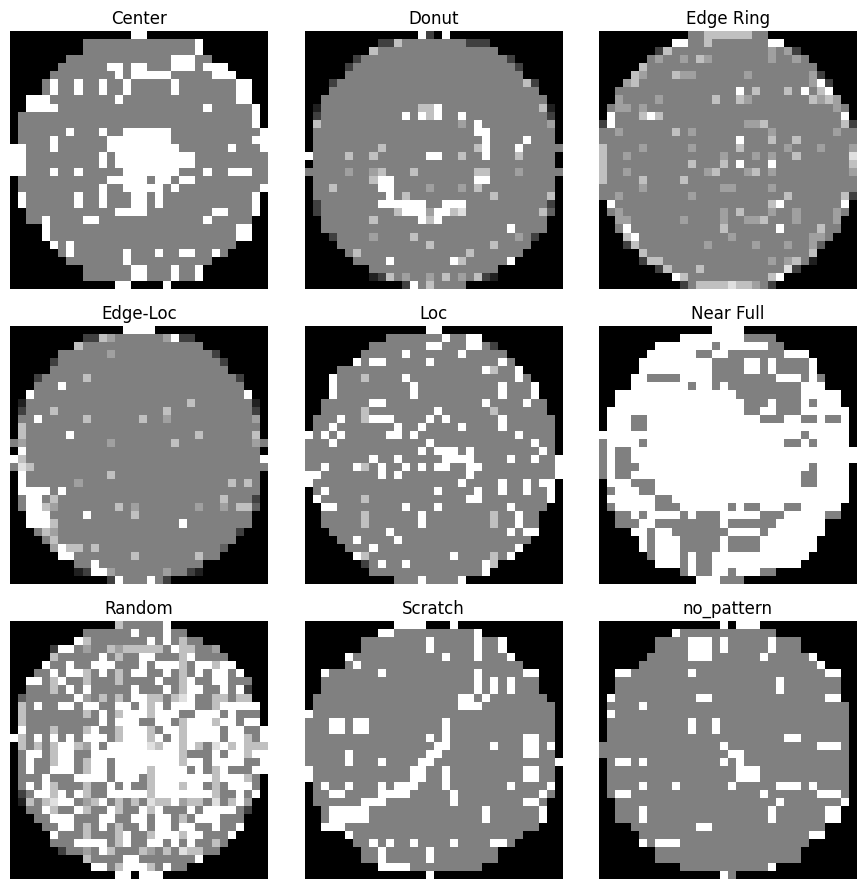

In [14]:

import os
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR_3 = Path(os.environ.get('AICE_IMG_DIR', 'aice_08_images'))

if not (IMG_DIR_3 / '03_train').exists() or not (IMG_DIR_3 / '03_test').exists():
    with zipfile.ZipFile('03_images.zip') as z:
        z.extractall(IMG_DIR_3)

train_3 = pd.read_csv('03_train.csv')
test_3 = pd.read_csv('03_test_x.csv')

classes_3 = sorted(train_3['label'].unique())

train_paths_3 = [
    IMG_DIR_3 / '03_train' / label / name
    for name, label in zip(train_3['file_name'], train_3['label'])
]

test_paths_3 = [
    IMG_DIR_3 / '03_test' / name
    for name in test_3['file_name']
]

print('데이터 구조')
display(pd.DataFrame({
    '구분': ['학습', '테스트'],
    '이미지 수': [len(train_3), len(test_3)],
    '컬럼 수': [train_3.shape[1], test_3.shape[1]]
}))

print('클래스별 이미지 분포')
counts_3 = train_3['label'].value_counts()

display(pd.DataFrame({
    '이미지 수': counts_3,
    '비율(%)': (counts_3 / len(train_3) * 100).round(2)
}))

print('이미지 파일 확인')
missing_train_3 = sum(not p.is_file() for p in train_paths_3)
missing_test_3 = sum(not p.is_file() for p in test_paths_3)

display(pd.DataFrame({
    '확인 항목': [
        '학습 파일 누락',
        '테스트 파일 누락',
        '정답 결측치',
        '클래스 수'
    ],
    '결과': [
        missing_train_3,
        missing_test_3,
        train_3['label'].isna().sum(),
        len(classes_3)
    ]
}))

assert missing_train_3 == 0
assert missing_test_3 == 0

with Image.open(train_paths_3[0]) as img:
    print('학습 이미지 크기:', img.size)
    print('학습 이미지 모드:', img.mode)
    print('학습 이미지 픽셀값:', np.unique(np.array(img)))

with Image.open(test_paths_3[0]) as img:
    print('테스트 이미지 크기:', img.size)
    print('테스트 이미지 모드:', img.mode)
    print('테스트 이미지 픽셀값:', np.unique(np.array(img)))

print('클래스별 대표 이미지')

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for ax, label in zip(axes.flat, classes_3):
    sample_path = (
        IMG_DIR_3 / '03_train' / label /
        train_3.loc[train_3['label'] == label, 'file_name'].iloc[0]
    )

    with Image.open(sample_path) as img:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)

    ax.set_title(label)
    ax.axis('off')

plt.tight_layout()
plt.show()


In [15]:

import hashlib
import numpy as np
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

np.random.seed(42)

def load_images_3(paths):
    images = []

    for path in paths:
        with Image.open(path) as img:
            arr = np.asarray(img.convert('L'), dtype=np.float32)
            images.append(arr)

    return np.stack(images)[..., np.newaxis] / 255.0

X_all_3 = load_images_3(train_paths_3)
X_test_3 = load_images_3(test_paths_3)

classes_3 = sorted(train_3['label'].unique())
class_to_idx_3 = {name: i for i, name in enumerate(classes_3)}

y_all_3 = train_3['label'].map(class_to_idx_3).to_numpy()

image_hashes_3 = np.array([
    hashlib.sha256(img.tobytes()).hexdigest()
    for img in X_all_3
])

splitter_3 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx_3, valid_idx_3 = next(
    splitter_3.split(
        X_all_3,
        y_all_3,
        groups=image_hashes_3
    )
)

X_train_3 = X_all_3[train_idx_3]
X_valid_3 = X_all_3[valid_idx_3]

y_train_3 = y_all_3[train_idx_3]
y_valid_3 = y_all_3[valid_idx_3]

print('데이터 분리 결과')
display(pd.DataFrame({
    '구분': ['학습', '검증', '테스트'],
    '이미지 수': [
        len(X_train_3),
        len(X_valid_3),
        len(X_test_3)
    ],
    '배열 크기': [
        str(X_train_3.shape),
        str(X_valid_3.shape),
        str(X_test_3.shape)
    ]
}))

print('클래스별 학습·검증 분포')
display(pd.DataFrame({
    '학습': pd.Series(
        y_train_3
    ).map(dict(enumerate(classes_3))).value_counts(),
    '검증': pd.Series(
        y_valid_3
    ).map(dict(enumerate(classes_3))).value_counts()
}).reindex(classes_3))

print('정규화 확인')
display(pd.DataFrame({
    '확인 항목': [
        '최소 픽셀값',
        '최대 픽셀값',
        '픽셀 자료형',
        '라벨 종류 수',
        '동일 픽셀 이미지 중복 수',
        '학습·검증 동일 이미지 수'
    ],
    '결과': [
        float(X_train_3.min()),
        float(X_train_3.max()),
        str(X_train_3.dtype),
        len(np.unique(y_all_3)),
        len(image_hashes_3) - len(set(image_hashes_3)),
        len(
            set(image_hashes_3[train_idx_3])
            & set(image_hashes_3[valid_idx_3])
        )
    ]
}))

assert X_train_3.min() >= 0
assert X_train_3.max() <= 1
assert X_train_3.shape[1:] == (32, 32, 1)
assert len(np.unique(y_train_3)) == 9
assert len(np.unique(y_valid_3)) == 9

assert not (
    set(image_hashes_3[train_idx_3])
    & set(image_hashes_3[valid_idx_3])
)


데이터 분리 결과


,구분,이미지 수,배열 크기
0,학습,3789,"(3789, 32, 32, 1)"
1,검증,946,"(946, 32, 32, 1)"
2,테스트,1184,"(1184, 32, 32, 1)"


클래스별 학습·검증 분포


,학습,검증
Center,399,81
Donut,68,20
Edge Ring,378,102
Edge-Loc,378,102
Loc,371,109
Near Full,14,7
Random,79,14
Scratch,171,42
no_pattern,1931,469


정규화 확인


,확인 항목,결과
0,최소 픽셀값,0.0
1,최대 픽셀값,1.0
2,픽셀 자료형,float32
3,라벨 종류 수,9
4,동일 픽셀 이미지 중복 수,2
5,학습·검증 동일 이미지 수,0


In [16]:

import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    BatchNormalization, Flatten, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam

tf.random.set_seed(42)

model_3_v1 = Sequential([
    Input(shape=(32, 32, 1)),

    Conv2D(32, 3, activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(32, 3, activation='relu', padding='same'),
    MaxPooling2D(2),
    Dropout(0.10),

    Conv2D(64, 3, activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(64, 3, activation='relu', padding='same'),
    MaxPooling2D(2),
    Dropout(0.15),

    Conv2D(128, 3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2),
    Dropout(0.20),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.30),

    Dense(len(classes_3), activation='softmax')
])

model_3_v1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_3_v1.summary()

print('총 파라미터 수:', model_3_v1.count_params())
print('입력 이미지:', X_train_3.shape[1:])
print('출력 클래스 수:', len(classes_3))
print('학습은 아직 시작하지 않았습니다.')


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 403,177 (1.54 MB)

 Trainable params: 402,729 (1.54 MB)

 Non-trainable params: 448 (1.75 KB)

총 파라미터 수: 403177
입력 이미지: (32, 32, 1)
출력 클래스 수: 9
학습은 아직 시작하지 않았습니다.


In [17]:

import tensorflow as tf
import numpy as np
import pandas as pd
from pathlib import Path

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
)
from tensorflow.keras.models import load_model
from sklearn.metrics import accuracy_score, classification_report

checkpoint_3_v1 = Path('candidate_3_cnn_v1.keras')

if checkpoint_3_v1.exists():
    raise FileExistsError('기존 CNN v1 체크포인트를 보존하세요.')

class_counts_3 = np.bincount(
    y_train_3,
    minlength=len(classes_3)
)

weights_3 = np.sqrt(
    len(y_train_3) / (len(classes_3) * class_counts_3)
)
weights_3 = np.minimum(weights_3, 4.0)

class_weights_3 = {
    i: float(w) for i, w in enumerate(weights_3)
}

print('클래스별 학습 가중치')
display(pd.DataFrame({
    '클래스': classes_3,
    '학습 이미지 수': class_counts_3,
    '가중치': weights_3.round(3)
}))

augmenter_3 = ImageDataGenerator(
    horizontal_flip=True,
    vertical_flip=True
)

train_generator_3 = augmenter_3.flow(
    X_train_3,
    y_train_3,
    batch_size=32,
    shuffle=True,
    seed=42
)

callbacks_3_v1 = [
    ModelCheckpoint(
        str(checkpoint_3_v1),
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor='val_accuracy',
        mode='max',
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history_3_v1 = model_3_v1.fit(
    train_generator_3,
    validation_data=(X_valid_3, y_valid_3),
    epochs=30,
    class_weight=class_weights_3,
    callbacks=callbacks_3_v1,
    verbose=2
)

best_model_3_v1 = load_model(str(checkpoint_3_v1))

valid_probs_3_v1 = best_model_3_v1.predict(
    X_valid_3,
    verbose=0
)
valid_pred_3_v1 = np.argmax(valid_probs_3_v1, axis=1)

best_epoch_3_v1 = int(
    np.argmax(history_3_v1.history['val_accuracy'])
)

valid_acc_3_v1 = accuracy_score(
    y_valid_3,
    valid_pred_3_v1
)

print('CNN v1 학습 결과')
display(pd.DataFrame({
    '확인 항목': [
        '실제 학습 Epoch',
        '최고 성능 Epoch',
        '해당 Epoch 학습 Accuracy(%)',
        '저장 모델 검증 Accuracy(%)',
        '문제 목표 83% 달성',
        '만점 기준 74.7% 달성',
        '체크포인트'
    ],
    '결과': [
        len(history_3_v1.history['loss']),
        best_epoch_3_v1 + 1,
        round(
            history_3_v1.history['accuracy'][best_epoch_3_v1] * 100,
            2
        ),
        round(valid_acc_3_v1 * 100, 2),
        valid_acc_3_v1 >= 0.83,
        valid_acc_3_v1 >= 0.747,
        str(checkpoint_3_v1)
    ]
}))

report_3_v1 = classification_report(
    y_valid_3,
    valid_pred_3_v1,
    labels=list(range(len(classes_3))),
    target_names=classes_3,
    output_dict=True,
    zero_division=0
)

class_result_3_v1 = pd.DataFrame(report_3_v1).T

print('클래스별 검증 성능')
display(
    class_result_3_v1.loc[
        classes_3,
        ['precision', 'recall', 'f1-score', 'support']
    ].round(3)
)


클래스별 학습 가중치


,클래스,학습 이미지 수,가중치
0,Center,399,1.027
1,Donut,68,2.488
2,Edge Ring,378,1.055
3,Edge-Loc,378,1.055
4,Loc,371,1.065
5,Near Full,14,4.000
6,Random,79,2.308
7,Scratch,171,1.569
8,no_pattern,1931,0.467


Epoch 1/30

Epoch 1: val_accuracy improved from None to 0.10782, saving model to candidate_3_cnn_v1.keras

Epoch 1: finished saving model to candidate_3_cnn_v1.keras
119/119 - 52s - 439ms/step - accuracy: 0.4840 - loss: 1.5667 - val_accuracy: 0.1078 - val_loss: 6.3879 - learning_rate: 0.0010
Epoch 2/30

Epoch 2: val_accuracy did not improve from 0.10782
119/119 - 46s - 388ms/step - accuracy: 0.6698 - loss: 1.0080 - val_accuracy: 0.1078 - val_loss: 4.0775 - learning_rate: 0.0010
Epoch 3/30

Epoch 3: val_accuracy improved from 0.10782 to 0.61311, saving model to candidate_3_cnn_v1.keras

Epoch 3: finished saving model to candidate_3_cnn_v1.keras
119/119 - 44s - 369ms/step - accuracy: 0.7184 - loss: 0.8942 - val_accuracy: 0.6131 - val_loss: 1.3160 - learning_rate: 0.0010
Epoch 4/30

Epoch 4: val_accuracy did not improve from 0.61311
119/119 - 48s - 401ms/step - accuracy: 0.7509 - loss: 0.8060 - val_accuracy: 0.4313 - val_loss: 1.2063 - learning_rate: 0.0010
Epoch 5/30

Epoch 5: val_accura

,확인 항목,결과
0,실제 학습 Epoch,28
1,최고 성능 Epoch,21
2,해당 Epoch 학습 Accuracy(%),88.1
3,저장 모델 검증 Accuracy(%),88.79
4,문제 목표 83% 달성,True
5,만점 기준 74.7% 달성,True
6,체크포인트,candidate_3_cnn_v1.keras


클래스별 검증 성능


,precision,recall,f1-score,support
Center,0.949,0.926,0.938,81.0
Donut,0.833,1.000,0.909,20.0
Edge Ring,0.980,0.980,0.980,102.0
Edge-Loc,0.921,0.804,0.859,102.0
Loc,0.820,0.670,0.737,109.0
Near Full,1.000,0.571,0.727,7.0
Random,0.636,1.000,0.778,14.0
Scratch,0.514,0.452,0.481,42.0
no_pattern,0.906,0.966,0.935,469.0


In [18]:

import numpy as np
import pandas as pd
from pathlib import Path
from tensorflow.keras.models import load_model
from sklearn.metrics import accuracy_score

model_path_3 = Path('candidate_3_cnn_v1.keras')
csv_path_3 = Path('candidate_3_cnn_v1.csv')

if not model_path_3.exists():
    raise FileNotFoundError('저장된 CNN 모델을 찾을 수 없습니다.')

if csv_path_3.exists():
    raise FileExistsError('후보 CSV가 이미 존재합니다.')

loaded_model_3 = load_model(str(model_path_3))

valid_probs_3 = loaded_model_3.predict(
    X_valid_3, verbose=0
)
valid_pred_3 = np.argmax(valid_probs_3, axis=1)

valid_acc_3 = accuracy_score(y_valid_3, valid_pred_3)

assert np.array_equal(valid_pred_3, valid_pred_3_v1)

test_probs_3 = loaded_model_3.predict(
    X_test_3, verbose=0
)

assert test_probs_3.shape == (len(test_3), len(classes_3))
assert np.isfinite(test_probs_3).all()
assert np.allclose(test_probs_3.sum(axis=1), 1.0, atol=1e-4)

test_pred_idx_3 = np.argmax(test_probs_3, axis=1)
test_pred_labels_3 = np.array(classes_3)[test_pred_idx_3]

candidate_csv_3 = test_3.copy()
candidate_csv_3['label'] = test_pred_labels_3
candidate_csv_3.to_csv(csv_path_3, index=False)

saved_csv_3 = pd.read_csv(csv_path_3)

assert saved_csv_3.columns.tolist() == ['file_name', 'label']
assert len(saved_csv_3) == len(test_3)
assert saved_csv_3['file_name'].equals(test_3['file_name'])
assert saved_csv_3['label'].notna().all()
assert saved_csv_3['label'].isin(classes_3).all()

assert np.array_equal(
    saved_csv_3['label'].to_numpy(),
    test_pred_labels_3
)

print('후보 파일 검증 결과')
display(pd.DataFrame({
    '확인 항목': [
        '모델 재불러오기',
        '저장 모델 검증 Accuracy(%)',
        '이전 검증 예측 일치',
        '테스트 예측 행 수',
        'CSV 컬럼 및 행 순서',
        '예측 결측치',
        '예측 라벨 유효성',
        '후보 CSV'
    ],
    '결과': [
        '정상',
        round(valid_acc_3 * 100, 2),
        '일치',
        len(test_pred_labels_3),
        '정상',
        saved_csv_3['label'].isna().sum(),
        '정상',
        str(csv_path_3)
    ]
}))

print('테스트 예측 클래스 분포')
display(
    saved_csv_3['label']
    .value_counts()
    .reindex(classes_3, fill_value=0)
    .to_frame('예측 건수')
)


후보 파일 검증 결과


,확인 항목,결과
0,모델 재불러오기,정상
1,저장 모델 검증 Accuracy(%),88.79
2,이전 검증 예측 일치,일치
3,테스트 예측 행 수,1184
4,CSV 컬럼 및 행 순서,정상
5,예측 결측치,0
6,예측 라벨 유효성,정상
7,후보 CSV,candidate_3_cnn_v1.csv


테스트 예측 클래스 분포


,예측 건수
label,
Center,112
Donut,22
Edge Ring,119
Edge-Loc,95
Loc,117
Near Full,5
Random,22
Scratch,41
no_pattern,651


In [19]:

import shutil
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path
from tensorflow.keras.models import load_model

source_model_3 = Path('candidate_3_cnn_v1.keras')
source_csv_3 = Path('candidate_3_cnn_v1.csv')

answer_model_3 = Path('answer_3.keras')
answer_csv_3 = Path('answer_3.csv')

if not source_model_3.exists() or not source_csv_3.exists():
    raise FileNotFoundError('후보 파일을 찾을 수 없습니다.')

if answer_model_3.exists() or answer_csv_3.exists():
    raise FileExistsError('정식 제출 파일이 이미 존재합니다.')

shutil.copy2(source_model_3, answer_model_3)
shutil.copy2(source_csv_3, answer_csv_3)

def file_hash_3(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert file_hash_3(source_model_3) == file_hash_3(answer_model_3)
assert file_hash_3(source_csv_3) == file_hash_3(answer_csv_3)

check_model_3 = load_model(str(answer_model_3))
check_csv_3 = pd.read_csv(answer_csv_3)

assert check_csv_3.columns.tolist() == ['file_name', 'label']
assert len(check_csv_3) == len(test_3)
assert check_csv_3['file_name'].equals(test_3['file_name'])
assert check_csv_3['label'].notna().all()
assert check_csv_3['label'].isin(classes_3).all()

check_probs_3 = check_model_3.predict(X_test_3, verbose=0)
check_labels_3 = np.array(classes_3)[
    np.argmax(check_probs_3, axis=1)
]

assert np.array_equal(
    check_labels_3,
    check_csv_3['label'].to_numpy()
)

display(pd.DataFrame({
    '확인 항목': [
        '모델 파일',
        '예측 CSV',
        '모델 파일 복사 일치',
        'CSV 파일 복사 일치',
        '모델 예측값과 CSV 일치',
        '제출 데이터 행 수',
        '예측 결측치',
        '예측 클래스 수'
    ],
    '결과': [
        str(answer_model_3),
        str(answer_csv_3),
        '정상',
        '정상',
        '정상',
        len(check_csv_3),
        check_csv_3['label'].isna().sum(),
        check_csv_3['label'].nunique()
    ]
}))


,확인 항목,결과
0,모델 파일,answer_3.keras
1,예측 CSV,answer_3.csv
2,모델 파일 복사 일치,정상
3,CSV 파일 복사 일치,정상
4,모델 예측값과 CSV 일치,정상
5,제출 데이터 행 수,1184
6,예측 결측치,0
7,예측 클래스 수,9


<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

압축을 풀고 폴더 구조(학습: 클래스별 폴더, 테스트: 한 폴더)를 확인합니다. 이미지를 같은 크기로 읽어 0~1 로 맞추고, 검증 데이터를 떼어 **작은 CNN**(또는 사전학습 모델 특징 + 분류기)을 학습합니다. 증강·Dropout·조기 종료로 과적합을 막고, 테스트는 `03_test_x.csv` 순서대로 예측하세요.

- 이 문항의 핵심: 학습 이미지는 4,735장, 테스트 이미지는 1,184장입니다. 클래스 비율이 고르지 않습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `pandas`, `tensorflow`, `Sequential`, `load_model`, `Input`, `Conv2D`, `MaxPooling2D`, `GlobalAveragePooling2D`, `Dense`, `Dropout`, `BatchNormalization`, `EarlyStopping`, `ModelCheckpoint`, `ReduceLROnPlateau`.

- 참고 문서: <https://keras.io/api/models/sequential/>
- 참고 문서: <https://keras.io/api/layers/convolution_layers/convolution2d/>
- 참고 문서: <https://keras.io/api/layers/pooling_layers/max_pooling2d/>
- 참고 문서: <https://keras.io/api/layers/core_layers/dense/>
- 참고 문서: <https://keras.io/api/layers/regularization_layers/dropout/>
- 참고 문서: <https://keras.io/api/callbacks/early_stopping/>

</details>

<details><summary>힌트 3단계 (코드 구조) - 3번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
import ____
from tensorflow.keras.models import ____, ____
from tensorflow.keras.layers import ____, ____, ____, ____, ____, ____, ____
from tensorflow.keras.callbacks import ____, ____, ____
from tensorflow.keras.utils import ____, ____
np.random.seed(____)

IMG_DIR = os.environ.get('____', '____')       # 압축을 풀 위치(브라우저판은 메모리 폴더 /tmp 사용)
if not os.path.exists(os.path.join(IMG_DIR, '____')):
    zipfile.ZipFile('03_images.zip').extractall(IMG_DIR)

train = pd.read_csv('03_train.csv')
test = pd.read_csv('03_test_x.csv')
CLASSES = sorted(train['____'].unique())
cls_idx = {c: i for i, c in enumerate(CLASSES)}

def read(paths):
    return np.stack([img_to_array(load_img(p, color_mode='____')) for p in paths]).astype('____') / ____


# ▷ 모델 구성(CNN 또는 사전학습 특징 추출)
# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_3.h5`(모델) · `answer_3.csv`(예측)

</details>